# RTK: from carrier phase to a centimetre fix

Carrier phase measures range far more finely than the code does. One GPS L1 carrier cycle
is about 19 cm long, while one C/A code chip spans about 293 m, and a receiver resolves a
small fraction of either. The catch is that the phase count starts when tracking starts: the
receiver follows every change of the range to a few millimetres, but the number of whole
cycles already in flight is unknown. That unknown count is the carrier-phase ambiguity.

Real-time kinematic positioning (RTK) adds a base receiver at known coordinates near the
rover, the receiver whose position is wanted. The two see almost the same satellite errors,
so subtracting their observations removes most of them, and a second subtraction between
satellites removes the receiver clocks. A Kalman filter then estimates the position together
with real-valued ambiguities, the float solution, and an integer search decides at each
epoch whether the ambiguities can be fixed to whole numbers, which gives the fixed solution.

[Notebook 01](01-signal-chain.ipynb) shows where carrier phase comes from, and
[notebook 02](02-standalone-pvt.ipynb) builds the standalone solver that seeds this one. The
units and the differencing steps are introduced again below, so this notebook also reads on
its own. The [glossary](../../docs/fundamentals/glossary.md) defines single difference,
double difference, ambiguity and ratio test, and the shared [notation](README.md#notation)
records the symbols and their signs.

The example moves from USUD in Japan to two IGS stations in Matera, Italy: MATE is the base
and MAT1 the rover, about 11 m apart, observed from 00:00 to 01:00 GPS time on 2021-12-26.
A short baseline gives the two antennas nearly the same atmospheric paths, and EUREF's
combined SINEX solution gives both stations' marker coordinates, so the error of every
solution can be measured. A marker is the surveyed point the published coordinates refer
to; the RINEX headers give the offset from each marker to its antenna. The engine solves at
the antennas and reports the rover marker. Both stations stand still; the rover is simply
the station solved for, and the engine runs in its default kinematic mode, which starts the
position afresh at every epoch. The notebook reads the two stations' observation files and
no output of notebooks 01 or 02.

The main run uses GPS L1 C/A (`G1C`) and L2 P(Y) (`G2W`). Section 5 adds more signals and
section 6 compares the L1/L2 run with RTKLIB. The committed outputs come from the station
files; the first code cell prints which data path is active, and
[data paths](README.md#data-paths) describes the setup. Synthetic data: a generated rover
and base pair near USUD, with a three-cycle slip planted in G03's L1 phase halfway through;
sections 5 and 6 are skipped.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Ellipse
from support import (
    MAT1_MARKER,
    MATE_MARKER,
    RTK_BASE_WINDOW,
    RTK_SPAN,
    RTK_WINDOW,
    data_source,
    diagram_arrow,
    diagram_box,
    diagram_canvas,
    diagram_dot,
    diagram_label,
    diagram_line,
    diagram_text,
    elapsed_minutes,
    enu,
    figure,
    figure_note,
    rnx2rtkp_rtk,
    scratch_dir,
    synthetic_rtk_epochs,
    threshold_line,
    time_note,
)

from pyrx.codes import CA_CHIP_RATE
from pyrx.gpstime import C_LIGHT, WEEK_S
from pyrx.models import Station
from pyrx.plots import BAR, CATEGORIES, HIGHLIGHT, INK, LINES, MUTED
from pyrx.rinex import read_rinex_header, read_rinex_nav, read_rinex_observations
from pyrx.rtk import Rtk, RtkOptions, pair_epochs, solve_rtk
from pyrx.signals import wavelength

out = scratch_dir("03-rtk")
signals = ("G1C", "G2W")
src = data_source()
if src is not None:
    rover = read_rinex_observations(src.mat1_obs, signals, RTK_WINDOW)
    base = read_rinex_observations(src.mate_obs, signals, RTK_BASE_WINDOW)
    ephs, _ = read_rinex_nav(src.brdc_mixed)
    hb, hr = read_rinex_header(src.mate_obs), read_rinex_header(src.mat1_obs)
    # Published coordinates refer to markers; the header offsets locate the antennas.
    station, rover_delta, truth = Station(MATE_MARKER, hb.delta_enu), hr.delta_enu, MAT1_MARKER
else:
    rover, base, ephs, station, rover_delta, truth = synthetic_rtk_epochs()
# `truth` is the reference marker position: MAT1's published marker, or the synthetic
# generating position; every position error below is measured from it.
baseline = np.linalg.norm(truth - station.marker)
synthetic = src is None
print(f"{len(rover)} rover epochs, {len(base)} base epochs, marker baseline {baseline:.2f} m, "
      f"signals {', '.join(signals)}")
print(f"L1 wavelength {100 * wavelength('G1C'):.2f} cm, L2 {100 * wavelength('G2W'):.2f} cm; "
      f"C/A chip length {C_LIGHT / CA_CHIP_RATE:.0f} m")

running on the recordings named by PYRX_CAPTURES


121 rover epochs, 121 base epochs, marker baseline 10.72 m, signals G1C, G2W
L1 wavelength 19.03 cm, L2 24.42 cm; C/A chip length 293 m


## 1. The pair

A double difference needs both receivers' observations of the same moment. For each rover
epoch at time $t_r$, `pair_epochs` takes the latest base epoch at time $t_b$ no later than
$t_r + 25$ ms (the tolerance within which two timestamps count as simultaneous), and keeps it
only while its age

$$\tau = t_r - t_b$$

is at most 30 s. A rover epoch without a recent enough base epoch has no partner; nothing is
interpolated between base epochs. Within the tolerance, $\tau$ can be a few milliseconds
negative.

Age matters when the receivers log on different schedules. The measurement variance of the
filter (section 3) grows by $(c\,\sigma_{\mathrm{clock}}\,\tau)^2$, where $c$ is the speed
of light and $\sigma_{\mathrm{clock}}$ the receiver clock-stability setting, so older base
data counts for less. Here the question does not arise: both station files log on the same
30 s grid, and the synthetic builder gives both receivers the same timestamps, so every age
is zero.

The figure counts the satellites present in both observation records at each epoch. That is
availability before the solver screens anything (elevation mask, ephemeris, missing
signals), so it can exceed the number of satellites the solution uses.

121 of 121 rover epochs have a base epoch within 30 s; 6 to 8 satellites in common


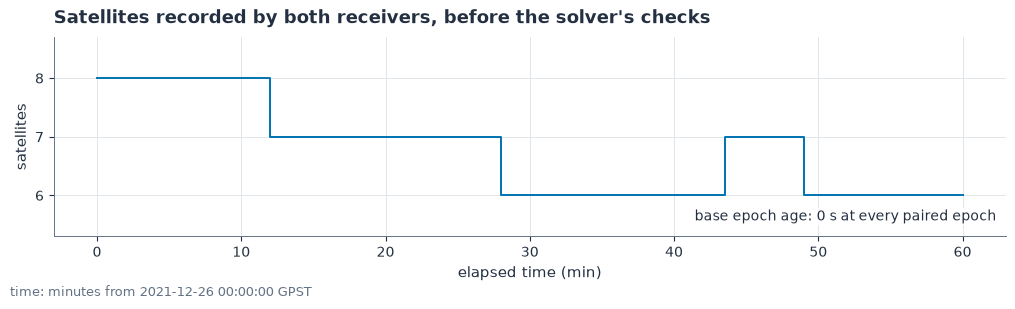

In [2]:
opt = RtkOptions()
# Pairs with a usable base epoch, for the figures; the solver screens measurements later.
pairs = [(r, b) for r, b in pair_epochs(rover, base, opt.max_age) if b is not None]
rov, bas = [r for r, _ in pairs], [b for _, b in pairs]
minutes = elapsed_minutes(rov, rover[0])
# Shared satellite records, including records the solver may later reject.
common = np.array([len(set(r.sats) & set(b.sats)) for r, b in pairs])
age = np.array([(r.week - b.week) * WEEK_S + r.tow - b.tow for r, b in pairs])
print(f"{len(pairs)} of {len(rover)} rover epochs have a base epoch within {opt.max_age:g} s; "
      f"{common.min()} to {common.max()} satellites in common")

steady = np.ptp(age) == 0
fig, axes = figure(1 if steady else 2, 1, figsize=(10, 2.8 if steady else 3.8), sharex=True,
                   squeeze=False)
ax = axes[0, 0]
ax.step(minutes, common, where="post", color=LINES[0])
ax.set_ylim(common.min() - 0.7, common.max() + 0.7)
ax.set_yticks(range(common.min(), common.max() + 1))
ax.set_ylabel("satellites")
ax.set_title("Satellites recorded by both receivers, before the solver's checks")
if steady:
    ax.text(0.99, 0.08, f"base epoch age: {age[0]:g} s at every paired epoch",
            transform=ax.transAxes, ha="right", color=INK, fontsize=10,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
else:
    ax_a = axes[1, 0]
    ax_a.step(minutes, age, where="post", color=LINES[0])
    threshold_line(ax_a, opt.max_age, f"pairing limit {opt.max_age:g} s")
    ax_a.set_ylim(0, max(32, age.max() + 2))
    ax_a.set_ylabel("base age (s)")
axes[-1, 0].set_xlabel("elapsed time (min)")
figure_note(fig, time_note(rover[0], synthetic))
plt.show()

## 2. Differencing

### The carrier-phase measurement

[Notebook 01](01-signal-chain.ipynb) follows the tracking loop into carrier phase: an
accumulated cycle count with an unknown integer offset. Multiplying it by the signal
wavelength expresses the same measurement in metres. For receiver $r$, satellite $s$ and one
signal of wavelength $\lambda$, the code and phase measurements are modelled as

$$P_r^s = \rho_r^s + c\,(\mathrm{dt}_r - \mathrm{dt}^s) + I_r^s + T_r^s + e_P,$$

$$\Phi_r^s = \lambda\varphi_r^s
 = \rho_r^s + c\,(\mathrm{dt}_r - \mathrm{dt}^s) - I_r^s + T_r^s + \lambda N_r^s + e_\Phi.$$

$P$ is the pseudorange and $\varphi$ the carrier phase in cycles; $\Phi$ is the same phase as
a length. $\rho$ is the geometric range, including the Earth's rotation during the signal's
flight. $\mathrm{dt}_r$ and $\mathrm{dt}^s$ are the receiver and satellite clock offsets in
seconds, and $c$ turns them into metres. $I$ is the ionospheric delay of the code; the same
ionosphere advances the carrier phase by the same amount, hence its minus sign in the phase
equation. $T$ is the tropospheric delay, the same for both. $N$ is the unknown whole number of
cycles of a continuous phase arc, and $e_P$, $e_\Phi$ collect noise, multipath and the effects
this model leaves out. Every term is in metres. The phase noise is a few millimetres against a
wavelength of 19 cm, which is why the phase is the precise measurement, once $N$ is known.

### Single and double differences

For any measurement $x$, the single difference of satellite $s$ is rover minus base, on the
same signal and at the same epoch: $\Delta x^s = x_r^s - x_b^s$. Both receivers see the same
satellite clock, so it cancels:

$$\Delta\Phi^s = \Delta\rho^s + c\,(\mathrm{dt}_r - \mathrm{dt}_b) - \Delta I^s + \Delta T^s
 + \lambda\,\Delta N^s + \Delta e_\Phi^s.$$

The two receiver clocks remain. The atmospheric terms become differences of two nearly equal
delays, which over 11 m are very small but not zero.

The double difference subtracts the single difference of a reference satellite $q$ from that
of satellite $s$, satellite minus reference: $\nabla\Delta x^{s,q} = \Delta x^s - \Delta x^q$.
The receiver-clock difference is the same for every satellite, so it cancels too. Dropping the
small differential atmosphere into the error term leaves

$$\nabla\Delta\Phi^{s,q} \simeq \nabla\Delta\rho^{s,q} + \lambda\,\nabla\Delta N^{s,q}
 + \nabla\Delta e_\Phi^{s,q}.$$

Both satellites belong to the same system and signal, so they share the wavelength and the
receiver clock terms. $\nabla\Delta N^{s,q}$ is a whole number of cycles: this is the integer
the rest of the notebook is after.

The figure below and the filter's measurement update use this satellite-minus-reference
order. The ambiguities that `pyrx` reports from its integer search (`Ambiguity.value`) run
the other way, reference minus satellite, so they estimate $-\nabla\Delta N^{s,q}$; section 3
returns to this where those values are plotted.

### The geometry that survives

Let $\mathbf d$ be the baseline, the rover antenna's position minus the base antenna's, and
$\mathbf e^s$ the unit vector from the receivers towards satellite $s$. Moving an antenna
towards a satellite shortens its range, so for a short baseline

$$\nabla\Delta\rho^{s,q} \simeq (\mathbf e^q - \mathbf e^s)^\mathsf T\,\mathbf d .$$

The antennas stay put, but the satellites cross the sky, so this projection of the baseline
onto two changing directions drifts over the hour. That drift carries the position
information. The engine itself uses the full model: before differencing it subtracts
from each receiver's code and phase the full predicted range, the satellite clock, and a
hydrostatic tropospheric delay mapped by the Niell function. It estimates no ionosphere, no
wet troposphere and no receiver clock, relying on the differences to remove them.

The diagram draws the four signal paths of one double difference, with the series' symbols.

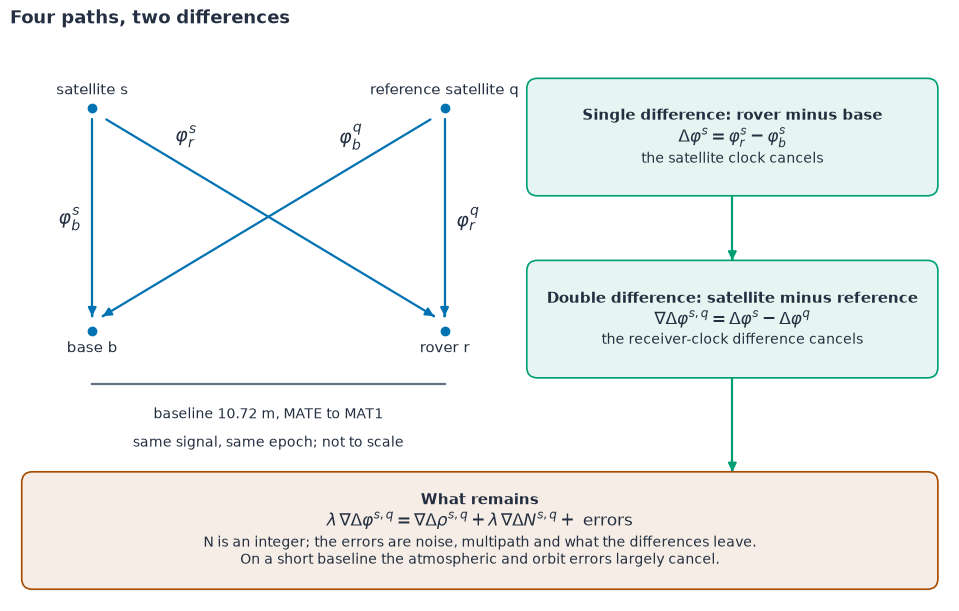

In [3]:
fig, ax = diagram_canvas(16, 9.6, "Four paths, two differences")
sat_s, sat_q, base_rx, rover_rx = (1.4, 8.4), (7.4, 8.4), (1.4, 4.6), (7.4, 4.6)
diagram_dot(ax, *sat_s, "satellite s")
diagram_dot(ax, *sat_q, "reference satellite q")
diagram_dot(ax, *base_rx, "base b", where="below")
diagram_dot(ax, *rover_rx, "rover r", where="below")
for (x0, y0), (x1, y1) in ((sat_s, base_rx), (sat_s, rover_rx), (sat_q, base_rx), (sat_q, rover_rx)):
    # stop each path short of the dots so the heads sit clear of them
    diagram_arrow(ax, [(x0 + 0.04 * (x1 - x0), y0 - 0.2), (x1 - 0.03 * (x1 - x0), y1 + 0.25)])
diagram_text(ax, 1.2, 6.5, r"$\varphi_b^s$", size=14, ha="right")
diagram_text(ax, 7.6, 6.5, r"$\varphi_r^q$", size=14, ha="left")
diagram_text(ax, 3.0, 7.9, r"$\varphi_r^s$", size=14)
diagram_text(ax, 5.8, 7.9, r"$\varphi_b^q$", size=14)
diagram_line(ax, [(1.4, 3.7), (7.4, 3.7)], width=1.6)
label = f"synthetic baseline {baseline:.1f} m" if synthetic else "baseline 10.72 m, MATE to MAT1"
diagram_text(ax, 4.4, 3.35, label, size=10, va="top")
diagram_text(ax, 4.4, 2.85, "same signal, same epoch; not to scale", size=10, va="top")

sd = diagram_box(
    ax, 8.8, 6.9, 7.0, 2.0, "Single difference: rover minus base",
    formula=r"$\Delta\varphi^s = \varphi_r^s - \varphi_b^s$",
    detail="the satellite clock cancels", role="measure",
)  # fmt: skip
dd_box = diagram_box(
    ax, 8.8, 3.8, 7.0, 2.0, "Double difference: satellite minus reference",
    formula=r"$\nabla\Delta\varphi^{s,q} = \Delta\varphi^s - \Delta\varphi^q$",
    detail="the receiver-clock difference cancels", role="measure",
)  # fmt: skip
diagram_arrow(ax, [sd.bottom, dd_box.top], role="measure")
rest = diagram_box(
    ax, 0.2, 0.2, 15.6, 2.0, "What remains",
    formula=r"$\lambda\,\nabla\Delta\varphi^{s,q} = \nabla\Delta\rho^{s,q}"
    r" + \lambda\,\nabla\Delta N^{s,q} + $ errors",
    detail="N is an integer; the errors are noise, multipath and what the differences leave."
    "\nOn a short baseline the atmospheric and orbit errors largely cancel.",
    role="highlight",
)  # fmt: skip
diagram_arrow(ax, [dd_box.bottom, (dd_box.bottom[0], rest.y + rest.height)], role="measure")
plt.show()

### Differencing real phases

The next figure takes raw L1 phases in cycles, before any of the engine's corrections, and
removes each trace's mean so its changes show. The pair plotted is chosen for display only.
The display reference is the satellite with the highest mean L1 C/N0 among those present at
every epoch (G10 on the station path, against G08). The filter makes its own choice: for its
measurements it takes the satellite highest in the sky, for each system and signal at each
epoch, the measurement reference.

On the station path the two single differences share sharp excursions, the receiver-clock
difference, but drift with different slopes, the satellite-dependent geometry. The double
difference loses the excursions and keeps a smooth line. It falls by about 29 cycles over the
hour, 5.6 m of path difference, produced by an 11 m baseline seen along two turning
sightlines while neither antenna moves. Removing the mean also removes the constant integer,
so the plot cannot show the integer itself.

Synthetic data: the generated receiver clocks are constant offsets, so the single
differences show geometry alone. The plotted satellite is G03, whose rover L1 phase gains
three cycles halfway through: its single difference and the double difference step together.
Dashed lines mark steps of more than one cycle between neighbouring points, a display rule of
this figure; the engine's own slip test is described in section 3.

Read more: [RTK](../../docs/fundamentals/09-rtk.md).

L1 phase display: G08 minus G10 (display reference); double difference changes by -29.4 cycles, -5.60 m


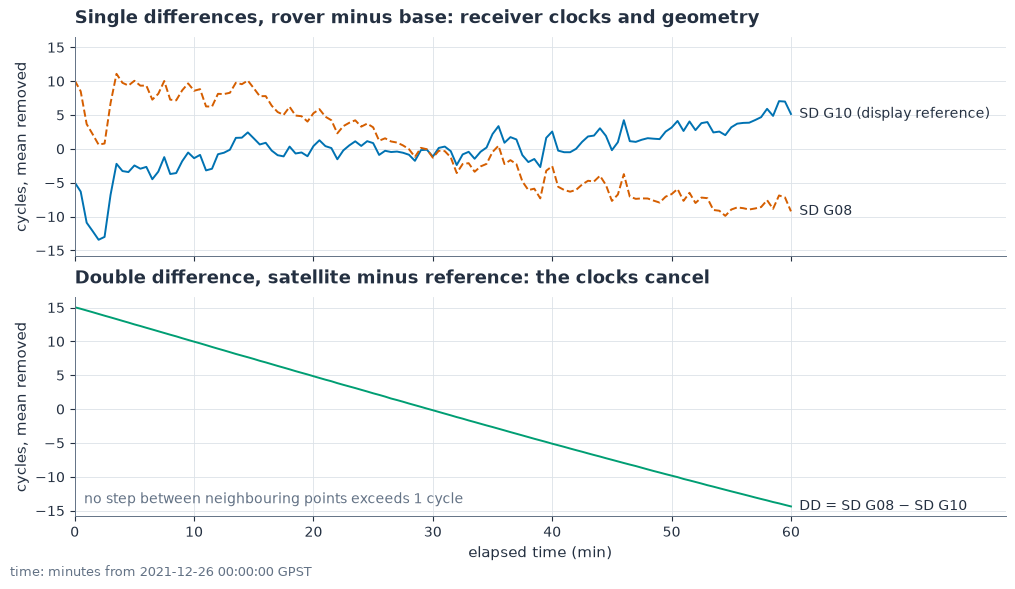

In [4]:
def phase(obs_list, sat, sig):
    j = obs_list[0].signals.index(sig)
    return np.array(
        [o.carrier_phase[o.sats.index(sat), j] if sat in o.sats else np.nan for o in obs_list]
    )


# Satellites present in every pair, so the display need not switch references.
always = [s for s in pairs[0][0].sats if all(s in r.sats and s in b.sats for r, b in pairs)]
# Rank by mean rover L1 C/N0, a signal-strength measure, only for this figure.
strength = {s: np.nanmean([r.cn0[r.sats.index(s), 0] for r in rov]) for s in always}
ref_sat, sat = sorted(always, key=lambda s: -strength[s])[:2]
if "G03" in always and synthetic:
    sat = "G03"  # the deliberately slipped satellite of the synthetic pair
# phase() returns cycles; both single differences are rover minus base, and the double
# difference is satellite minus display reference.
sd_ref = phase(rov, ref_sat, "G1C") - phase(bas, ref_sat, "G1C")
sd_sat = phase(rov, sat, "G1C") - phase(bas, sat, "G1C")
dd = sd_sat - sd_ref
# Steps over one cycle between neighbouring points; a display rule, not Rtk's slip test.
jumps = np.flatnonzero(np.abs(np.diff(dd)) > 1.0) + 1
print(f"L1 phase display: {sat} minus {ref_sat} (display reference); "
      f"double difference changes by {dd[-1] - dd[0]:+.1f} cycles, "
      f"{(dd[-1] - dd[0]) * wavelength('G1C'):+.2f} m")

fig, (ax_s, ax_d) = figure(2, 1, figsize=(10, 5.6), sharex=True, sharey=True)
end = minutes[-1]
for y, text, color, style in (
    (sd_ref - np.nanmean(sd_ref), f"SD {ref_sat} (display reference)", LINES[0], "-"),
    (sd_sat - np.nanmean(sd_sat), f"SD {sat}", LINES[1], "--"),
):
    ax_s.plot(minutes, y, color=color, linestyle=style)
    ax_s.annotate(text, (end, y[-1]), xytext=(6, 0), textcoords="offset points",
                  va="center", fontsize=10, color=INK)
ax_s.set_ylabel("cycles, mean removed")
ax_s.set_title("Single differences, rover minus base: receiver clocks and geometry")
y = dd - np.nanmean(dd)
ax_d.plot(minutes, y, color=LINES[2])
ax_d.annotate(f"DD = SD {sat} − SD {ref_sat}", (end, y[-1]), xytext=(6, 0),
              textcoords="offset points", va="center", fontsize=10, color=INK)
for k in jumps:
    ax_d.axvline(minutes[k], color=HIGHLIGHT, linestyle="--", linewidth=1)
    ax_d.annotate(f"step {dd[k] - dd[k - 1]:+.2f} cycles", (minutes[k], 0.92),
                  xycoords=ax_d.get_xaxis_transform(), xytext=(5, 0),
                  textcoords="offset points", color=HIGHLIGHT, fontsize=10, va="top")
if not len(jumps):
    ax_d.text(0.01, 0.06, "no step between neighbouring points exceeds 1 cycle",
              transform=ax_d.transAxes, color=MUTED, fontsize=10)
ax_d.set_ylabel("cycles, mean removed")
ax_d.set_xlabel("elapsed time (min)")
ax_d.set_xlim(0, end * 1.3)
ax_d.set_xticks(np.arange(0, end + 1, 10 if end > 30 else 5))
ax_d.set_title("Double difference, satellite minus reference: the clocks cancel")
figure_note(fig, time_note(rover[0], synthetic))
plt.show()

## 3. The float solution

Each step starts with a standalone position from `pvt.solve_epoch`, the solver of
[notebook 02](02-standalone-pvt.ipynb), using the rover's GPS L1 C/A pseudoranges. Carrier
phase and the base observations then refine it. Before any integer is chosen, the engine
estimates the position and the ambiguities as real numbers: this is the float solution. A
Kalman filter produces it, combining each epoch's measurements with the ambiguity
information carried over from earlier epochs. Its covariance records how uncertain each
estimate is and how the errors of different estimates move together.

### The state and its covariance

The filter's state vector is

$$\mathbf x = \begin{bmatrix}\mathbf p \\ \mathbf b\end{bmatrix},$$

where $\mathbf p$ is the rover antenna position in Earth-centred, Earth-fixed (ECEF)
coordinates, in metres, and $\mathbf b$ holds one real-valued ambiguity state $b_{s,g}$ per
satellite $s$ and signal $g$, in cycles: the single-differenced (rover minus base) ambiguity
$\Delta N^s$ plus an offset common to every state of that signal. The common offset cancels in
any double difference, and the integers are only imposed on those differences, later. The
filter never stores a double-differenced ambiguity. The covariance matrix $P$ holds the
variances of the position and of every state, and their cross-covariances.

### What happens at each epoch

In the default kinematic mode, each epoch first replaces $\mathbf p$ by the single-point seed
and resets its covariance to 30 m standard deviation on each axis, clearing the
cross-covariances between the position and the ambiguities. The position therefore carries
nothing over from the previous epoch; the ambiguity block of $P$ does, and that is where the
filter's memory lives.

An existing ambiguity state that has usable phase and code this epoch has its variance grown
by $q_b^2\,|\Delta t|$, where $\Delta t$ is the time since the previous rover epoch and
$q_b = 10^{-4}$ cycles per square root of a second. Over a 30 s interval that adds about
$5\times10^{-4}$ cycles of standard deviation, so the ambiguities are treated as nearly
constant. The existing states of each signal are also shifted together by one phase-minus-code
offset, which keeps them aligned with the current receiver clocks; the shift cancels in every
double difference. A satellite seen for the first time gets a new state, started from its
phase minus code with a standard deviation of 30 cycles.

### The measurement model and its weights

At the seeded position the engine forms double-differenced phase and code residuals for every
satellite against the measurement reference $q$, the highest satellite of the same system and
signal at this epoch. Linearised, a phase residual $\delta z_\Phi^{s,q}$ (measured minus
predicted, in metres) depends on the corrections $\delta\mathbf p$ and $\delta b$ to the
current estimates as

$$\delta z_\Phi^{s,q} \simeq (\mathbf e^q - \mathbf e^s)^\mathsf T\,\delta\mathbf p
 + \lambda_g\,(\delta b_{s,g} - \delta b_{q,g}) + \eta_\Phi ,$$

with $\lambda_g$ the wavelength of signal $g$ and $\eta_\Phi$ the measurement error. One row of
the design matrix $H$ holds $\mathbf e^q - \mathbf e^s$ in the position columns,
$+\lambda_g$ in satellite $s$'s ambiguity column and $-\lambda_g$ in $q$'s. A code row has the
same position columns and no ambiguity columns. The code anchors the position coarsely; the
phase supplies the fine measurement. A residual larger than 30 m is dropped as an outlier.

The measurement covariance $R$ weights each difference by elevation, by measurement type and
by base age. The variance assigned to the single difference of satellite $s$ is

$$V_s = 2\left(a^2 + \frac{a^2}{\sin^2 E_s}\right) + (c\,\sigma_{\mathrm{clock}}\,\tau)^2 ,$$

where $E_s$ is the satellite's elevation, $a$ is 3 mm for phase and 100 times that for code,
$\sigma_{\mathrm{clock}} = 5\times10^{-12}$ and $\tau$ the base age. For phase, a satellite at
the zenith gets $\sqrt{V_s} = 6$ mm and one at the 15° mask about 17 mm. A double difference
against $q$ has variance $V_s + V_q$, and two differences sharing $q$ also share the
covariance $V_q$: their errors are correlated through the common reference.

### The update

Collect the residuals in the innovation vector $\mathbf v$. With $^-$ marking the state and
covariance before the measurement update and $^+$ after it, the engine computes

$$S = H P^- H^\mathsf T + R, \qquad K = P^- H^\mathsf T S^{-1},$$

$$\mathbf x^+ = \mathbf x^- + K\mathbf v, \qquad P^+ = (I - KH)\,P^- .$$

$S$ is the innovation covariance and $K$ the Kalman gain: how far each residual should move
each state, given their uncertainties and correlations. There is one update per epoch. Once the
ambiguity states are well determined, the update brings the position to a few centimetres,
although it was reset to 30 m a moment before, because the phase residuals tie it to those
ambiguities.

### Slips and outages

The ambiguity of a phase arc is only constant while the receiver keeps lock. The engine
treats a state as slipped when either receiver reports loss of lock in its RINEX indicator,
when either receiver's half-cycle flag changes, or when the geometry-free combination (the
system's first signal minus another signal, in metres) jumps by more than 0.05 m from one
epoch to the next. A slipped state is removed and started again from phase minus code. A
geometry-free jump cannot say which of the two signals slipped, so it restarts the
satellite's first-signal state as well. A state whose satellite has been missing for more
than five epochs is dropped; only epochs that reach the relative solution count towards that.

Both data paths show a restart. On the station path the rover reports a loss of lock on G21's
L2 phase 22 minutes into the hour; the engine restarts both of G21's states, from the jump in
the geometry-free combination as well as the flag. On the synthetic path the planted
three-cycle slip on G03's L1 phase carries no loss-of-lock flag; the engine finds it from the
same geometry-free jump and restarts both of G03's states.

The diagram puts one epoch of the filter together, with the exits that return no solution.

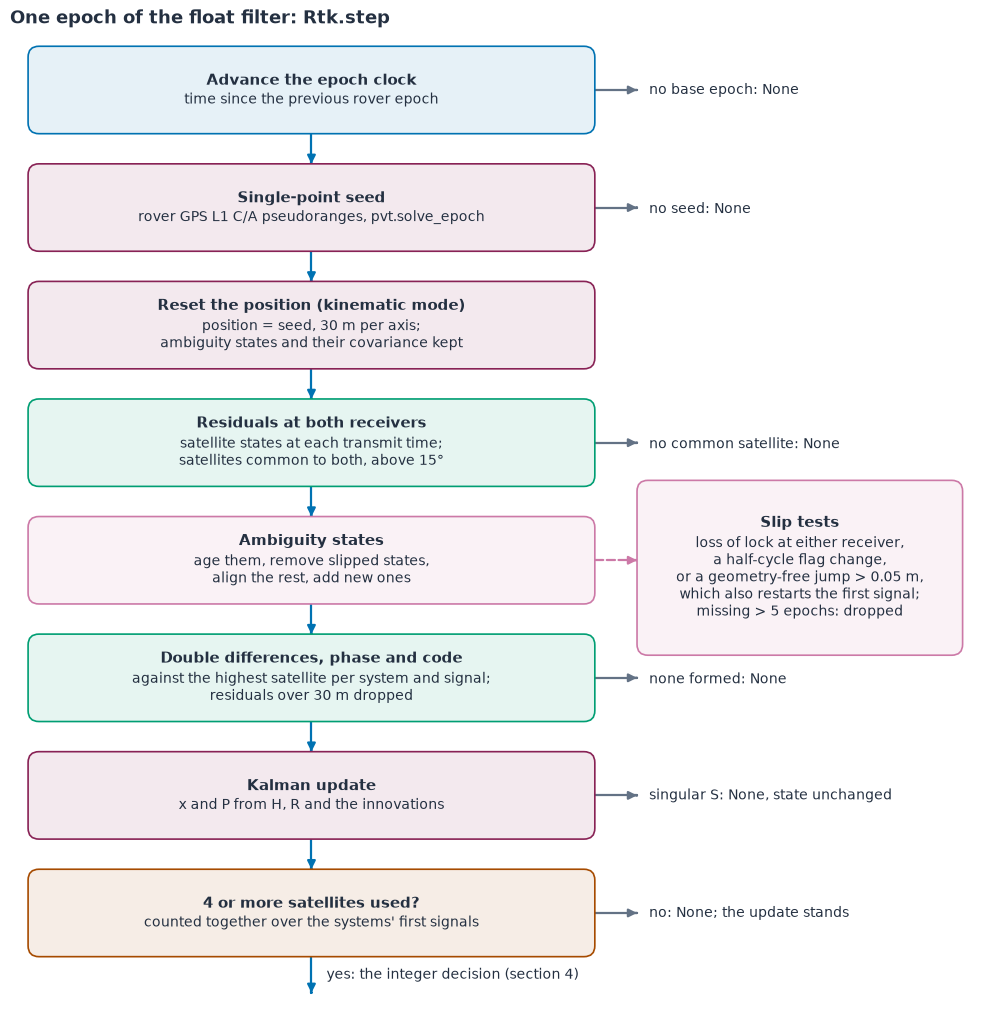

In [5]:
def exit_note(box, text):
    # a side exit of the flow: an arrow to the right, then its note
    y = box.right[1]
    diagram_arrow(ax, [box.right, (10.4, y)], role="context")
    diagram_text(ax, 10.6, y, text, size=10, ha="left")


fig, ax = diagram_canvas(16, 16.4, "One epoch of the float filter: Rtk.step")
steps = [  # title, detail, side exit, role
    ("Advance the epoch clock", "time since the previous rover epoch",
     "no base epoch: None", "flow"),
    ("Single-point seed", "rover GPS L1 C/A pseudoranges, pvt.solve_epoch",
     "no seed: None", "position"),
    ("Reset the position (kinematic mode)",
     "position = seed, 30 m per axis;\nambiguity states and their covariance kept",
     "", "position"),
    ("Residuals at both receivers",
     "satellite states at each transmit time;\nsatellites common to both, above 15°",
     "no common satellite: None", "measure"),
    ("Ambiguity states", "age them, remove slipped states,\nalign the rest, add new ones",
     "", "control"),
    ("Double differences, phase and code",
     "against the highest satellite per system and signal;\nresiduals over 30 m dropped",
     "none formed: None", "measure"),
    ("Kalman update", "x and P from H, R and the innovations",
     "singular S: None, state unchanged", "position"),
]
boxes = []
top = 14.8
for i, (title, detail, exit_text, role) in enumerate(steps):
    box = diagram_box(ax, 0.3, top - i * 1.95, 9.4, 1.45, title, detail, role=role)
    if boxes:
        diagram_arrow(ax, [boxes[-1].bottom, box.top], role="flow")
    if exit_text:
        exit_note(box, exit_text)
    boxes.append(box)
decide = diagram_box(ax, 0.3, top - 7 * 1.95, 9.4, 1.45,
                     "4 or more satellites used?", "counted together over the systems' first signals",
                     role="highlight")
diagram_arrow(ax, [boxes[-1].bottom, decide.top])
exit_note(decide, "no: None; the update stands")
diagram_arrow(ax, [decide.bottom, (decide.bottom[0], 0.55)], "yes: the integer decision "
              "(section 4)", (decide.bottom[0] + 0.25, 0.85), ha="left")
slips = diagram_box(
    ax, 10.4, 6.15, 5.4, 2.9, "Slip tests", "loss of lock at either receiver,\n"
    "a half-cycle flag change,\nor a geometry-free jump > 0.05 m,\nwhich also restarts the "
    "first signal;\nmissing > 5 epochs: dropped", role="control",
)  # fmt: skip
box5 = boxes[4]
diagram_arrow(ax, [box5.right, (slips.x, box5.right[1])], role="control")
plt.show()

### Reading the float figures

The code below runs the filter over every rover epoch, the way `solve_rtk` and the `pyrx-rtk`
command do: an epoch without a base epoch returns no solution but still advances the filter's
clock. Its printout counts the filter's states and the double-differenced ambiguities that
reach the integer search.

The first figure shows the float marker-position error in east, north and up, about the
reference marker. The shaded band around each trace has the same half-width in every panel,
the square root of the trace of the position covariance after the update:

$$\sigma_{\mathrm{plot}} = \sqrt{P^+_{XX} + P^+_{YY} + P^+_{ZZ}} .$$

$X$, $Y$, $Z$ are the three ECEF axes. Rotating into east, north and up preserves the sum of
the variances, so $\sigma_{\mathrm{plot}}$ is at least as large as the formal standard
deviation of any one component. It is a statement about the covariance and not a bound on
the actual error. On the station path the first band is about 1.6 m wide on either side,
already far inside the 30 m of the reset, and it narrows to about 4 cm by the end of the hour
as the ambiguities gather information, even though the position is re-seeded at every epoch.

121 epochs solved in 1 s
final filter: 12 single-difference ambiguity states plus 3 position coordinates
double differences eligible for the search per epoch: 10 to 12
first epoch search references: G1C: G08, G2W: G08
last epoch search references: G1C: G08, G2W: G08
first solved epoch: fix, ratio 18.7
band half-width: first epoch 1.62 m, last 4.14 cm


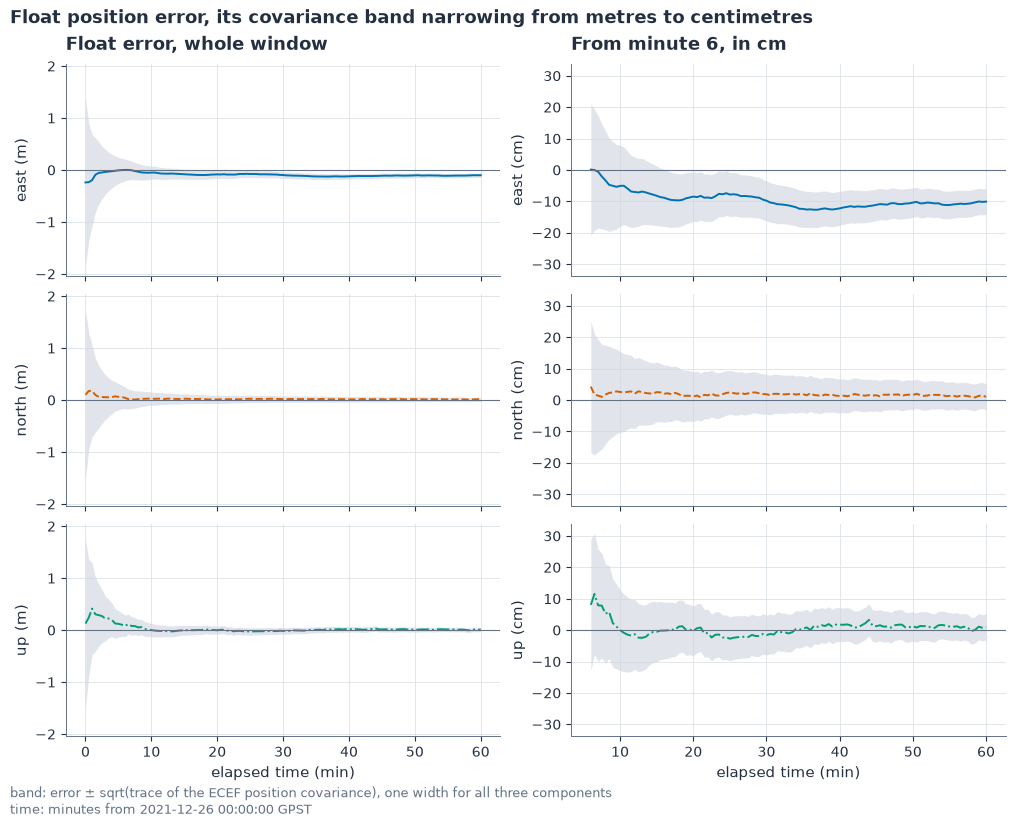

In [6]:
rtk = Rtk(ephs, station, rover_delta, opt)
t0 = time.perf_counter()
# Step every rover epoch, as solve_rtk does: one without a base returns None but still
# advances the filter's clock, so the ambiguity process noise sees the real interval.
steps = (rtk.step(r, b) for r, b in pair_epochs(rover, base, opt.max_age))
fixes = [f for f in steps if f is not None]
print(f"{len(fixes)} epochs solved in {time.perf_counter() - t0:.0f} s")
print(f"final filter: {len(rtk.keys)} single-difference ambiguity states "
      f"plus {len(rtk.x) - len(rtk.keys)} position coordinates")
print(f"double differences eligible for the search per epoch: "
      f"{min(f.nb for f in fixes)} to {max(f.nb for f in fixes)}")
for which, f in (("first", fixes[0]), ("last", fixes[-1])):
    refs = ", ".join(f"{g}: {q}" for g, q in sorted({(a.signal, a.ref) for a in f.ambiguities}))
    print(f"{which} epoch search references: {refs or 'none'}")
print(f"first solved epoch: {fixes[0].status}, ratio {fixes[0].ratio:.1f}")

tf = elapsed_minutes(fixes, rover[0])
float_err = enu(np.array([f.float_position for f in fixes]), truth)
# One width per epoch from the ECEF variances, drawn around every component.
sigma = np.array([np.linalg.norm(f.position_std) for f in fixes])
print(f"band half-width: first epoch {sigma[0]:.2f} m, last {sigma[-1] * 100:.2f} cm")

late = tf >= tf[0] + 0.1 * (tf[-1] - tf[0])
fig, axes = figure(3, 2, figsize=(10, 7.8), sharex="col")
for col, keep, scale, unit in ((0, np.ones_like(late), 1.0, "m"), (1, late, 100.0, "cm")):
    lim = 1.1 * np.max(np.abs(float_err[keep]) + sigma[keep, None]) * scale
    for j, name in enumerate(("east", "north", "up")):
        ax = axes[j, col]
        e, s = float_err[keep, j] * scale, sigma[keep] * scale
        ax.fill_between(tf[keep], e - s, e + s, color=BAR, alpha=0.6, linewidth=0)
        ax.plot(tf[keep], e, color=LINES[j], linestyle=("-", "--", "-.")[j])
        ax.axhline(0, color=MUTED, linewidth=0.8)
        ax.set_ylim(-lim, lim)
        ax.set_ylabel(f"{name} ({unit})")
axes[0, 0].set_title("Float error, whole window")
axes[0, 1].set_title(f"From minute {tf[late][0]:.0f}, in cm")
axes[2, 0].set_xlabel("elapsed time (min)")
axes[2, 1].set_xlabel("elapsed time (min)")
fig.suptitle("Float position error, its covariance band narrowing from metres to centimetres",
             x=0.0, ha="left", fontsize=13, fontweight="bold", color=INK)
figure_note(fig, "band: error ± sqrt(trace of the ECEF position covariance), one width for "
            "all three components\n" + time_note(rover[0], synthetic))
plt.show()

### Reading the ambiguity traces

The second figure plots the double-differenced ambiguities that the engine hands to its
integer search, not the single-differenced states it stores. Within each system and signal
the search takes the first eligible state in the filter's state order as its reference, the
search reference. A state keeps its place in that order; a state that restarts after a slip
moves to the end. On the station path that reference is G08 on both signals, so three
different reference satellites appear in this notebook: the display reference G10 of
section 2, the highest satellite that each epoch's measurements are differenced against, and
the search reference G08 plotted here.

`Ambiguity.value` is reference minus satellite,

$$\hat a^{q,s}_g = \hat b_{q,g} - \hat b_{s,g} \approx -\nabla\Delta N^{s,q}_g ,$$

where the hat marks a real-valued estimate, so a label such as `G08 − G10` reads reference
G08 minus satellite G10: the opposite order to the raw double difference of section 2. Each
curve is that value minus a comparison integer $n$. On a fixed epoch $n$ is the integer the
search accepted, drawn as a line; on a float epoch no integer has been accepted, and the open
dots use the nearest integer only to centre the display.

On the station path several offsets stay between about 0.4 and 0.8 cycles from zero while
every epoch is fixed. At minute 30 the formal standard deviations of these ambiguities reach
0.35 cycles (printed below), so such an offset lies within about two of its own standard
deviations, and for two of them, G08 − G23 and G08 − G32 on L1, the accepted integer is not
even the nearest one. The search judges the whole vector with its correlations, which
section 4 explains, and the marker error there checks the result independently. G21's
traces jump at minute 22, where its states restart. On the synthetic path G03's states
restart at minute 10 and its traces barely move, because the satellites that kept lock
already determine the position.

minute 30: formal standard deviations 0.06 to 0.35 cycles; accepted integer not the nearest for G08 − G23 G1C, G08 − G32 G1C


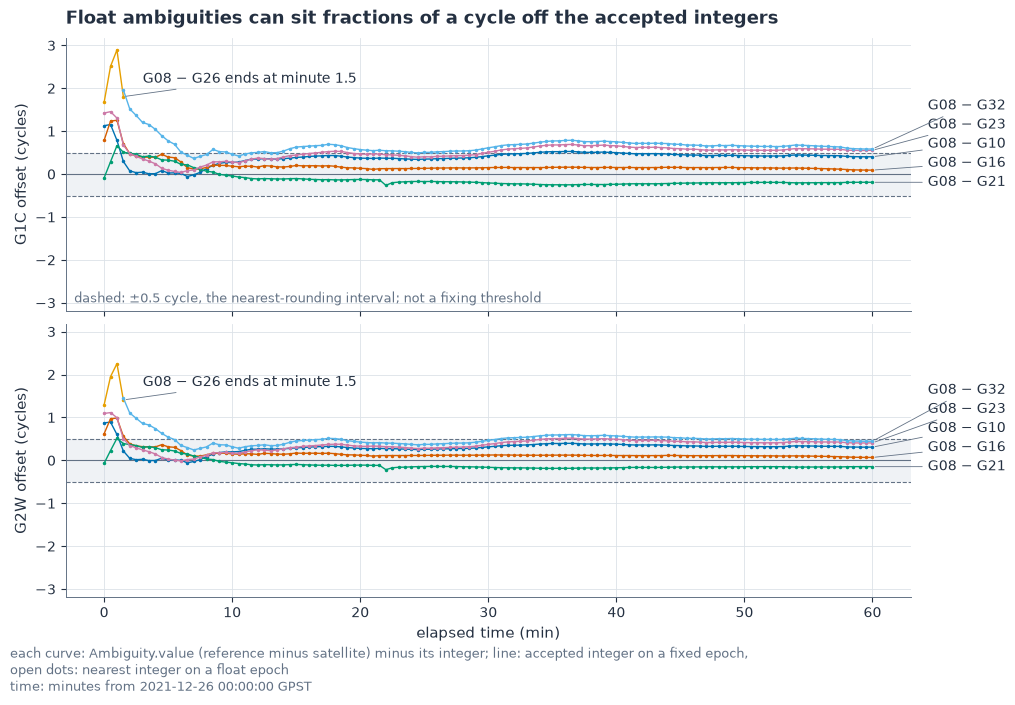

In [7]:
def end_labels(ax, items, gap=0.07):
    # Labels in a gutter right of the axes, one per (text, x, y) series end, spread apart.
    lo, hi = ax.get_ylim()
    items = sorted(items, key=lambda it: it[2])
    pos = [(y - lo) / (hi - lo) for _, _, y in items]
    for i in range(1, len(pos)):
        pos[i] = max(pos[i], pos[i - 1] + gap)
    shift = max(0.0, pos[-1] - 0.97) if pos else 0.0
    pos = [p - shift for p in pos]
    for (text, x, y), p in zip(items, pos):
        ax.annotate(text, (x, y), xytext=(1.02, p), textcoords="axes fraction",
                    va="center", fontsize=10, color=INK, annotation_clip=False,
                    arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.6})


# These are ambiguity offsets, not the filter's phase residuals: (ref, sat, signal) ->
# per-epoch value minus the comparison integer, NaN where the record is absent.
offsets, fixed_mask = {}, {}
for i, f in enumerate(fixes):
    for a in f.ambiguities:
        key = (a.ref, a.sat, a.signal)
        offsets.setdefault(key, np.full(len(fixes), np.nan))
        fixed_mask.setdefault(key, np.zeros(len(fixes), bool))
        # on a float epoch the nearest integer only centres the display; nothing was fixed
        n = a.integer if a.integer is not None else round(a.value)
        offsets[key][i] = a.value - n
        fixed_mask[key][i] = a.integer is not None
mid = len(fixes) // 2
stds = [a.std for a in fixes[mid].ambiguities]
far = [f"{a.ref} − {a.sat} {a.signal}" for a in fixes[mid].ambiguities
       if a.integer is not None and abs(a.value - a.integer) > 0.5]
print(f"minute {tf[mid]:.0f}: formal standard deviations {min(stds):.2f} to {max(stds):.2f} "
      f"cycles; accepted integer not the nearest for {', '.join(far) or 'none'}")
sats = sorted({k[1] for k in offsets})
color = {s: CATEGORIES[i % len(CATEGORIES)] for i, s in enumerate(sats)}
lim = 1.1 * max(0.6, np.nanmax(np.abs(np.concatenate(list(offsets.values())))))

fig, axes = figure(2, 1, figsize=(10, 6.4), sharex=True, sharey=True)
for ax, sig in zip(axes, signals):
    ax.axhspan(-0.5, 0.5, color=BAR, alpha=0.3, linewidth=0)
    for edge in (-0.5, 0.5):
        ax.axhline(edge, color=MUTED, linestyle="--", linewidth=0.8)
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.set_ylim(-lim, lim)
    labels = []
    for (q, s, g), y in sorted(offsets.items()):
        if g != sig:
            continue
        fx = fixed_mask[(q, s, g)]
        ax.plot(tf, np.where(fx, y, np.nan), color=color[s], linestyle="-", marker=".",
                markersize=3, linewidth=1)
        ax.plot(tf[~fx], y[~fx], "o", color=color[s], markerfacecolor="white", markersize=4)
        last = np.flatnonzero(np.isfinite(y))[-1]
        if tf[last] < 0.8 * tf[-1]:  # an early end gets its label at that point
            ax.annotate(f"{q} − {s} ends at minute {tf[last]:.1f}", (tf[last], y[last]),
                        xytext=(14, 10), textcoords="offset points", fontsize=10, color=INK,
                        arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 0.6})
        else:
            labels.append((f"{q} − {s}", tf[last], y[last]))
    end_labels(ax, labels)
    ax.set_ylabel(f"{sig} offset (cycles)")
axes[0].text(0.01, 0.03, "dashed: ±0.5 cycle, the nearest-rounding interval; "
             "not a fixing threshold", transform=axes[0].transAxes, fontsize=9, color=MUTED)
axes[0].set_title("Float ambiguities can sit fractions of a cycle off the accepted integers")
axes[1].set_xlabel("elapsed time (min)")
figure_note(fig, "each curve: Ambiguity.value (reference minus satellite) minus its integer; "
            "line: accepted integer on a fixed epoch,\nopen dots: nearest integer on a float "
            "epoch\n" + time_note(rover[0], synthetic))
plt.show()

## 4. Resolving the integers

### Integer least squares

The float solution gives real-valued ambiguities and their covariance. Resolving them means
finding the vector of integers that fits that joint estimate best. Let $\hat{\mathbf a}$ hold
the $m$ double-differenced float ambiguities in the search's reference-minus-satellite order,
and $Q_b$ their covariance in cycles squared. For a candidate integer vector $\mathbf n$
define the squared distance

$$s(\mathbf n) = (\hat{\mathbf a} - \mathbf n)^\mathsf T\, Q_b^{-1}\,(\hat{\mathbf a} - \mathbf n),
\qquad \check{\mathbf a} = \underset{\mathbf n \in \mathbb Z^m}{\arg\min}\; s(\mathbf n),$$

where $\mathbb Z^m$ is the set of integer vectors of length $m$ and the check mark marks the
chosen vector. The distance is measured in units of the uncertainty, along the directions the
covariance allows, so a candidate far from $\hat{\mathbf a}$ in a well-determined direction
costs much more than the same offset along a poorly determined one. Rounding each value on
its own ignores those directions, and the correlations between double differences are strong:
they share the reference satellite, and all of them share the position.

The picture below shows the effect on a made-up pair of ambiguities.

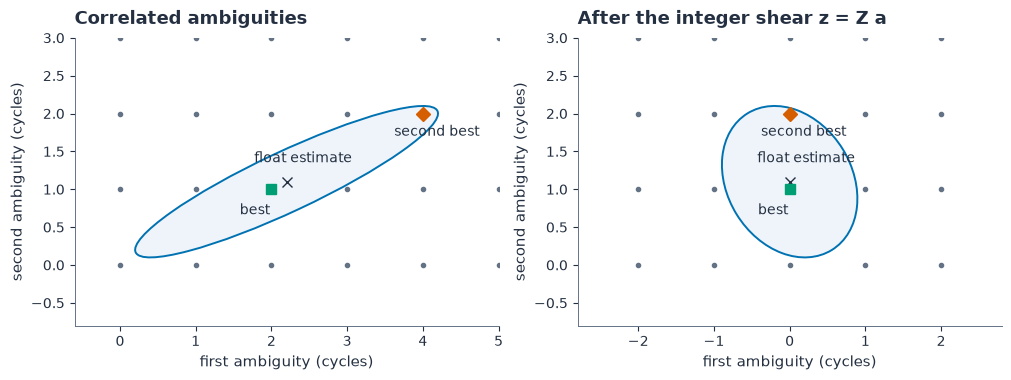

In [8]:
# A constructed two-ambiguity example, not an epoch of either data path.
toy_mean = np.array([2.2, 1.1])
toy_cov = np.array([[4.0, 1.8], [1.8, 1.0]])
toy_z = np.array([[1, -2], [0, 1]])  # integer shear with determinant 1
toy_grid = np.array([(i, j) for i in range(-6, 12) for j in range(-6, 8)])
toy_best, toy_second = np.array([2, 1]), np.array([4, 2])

fig, axes = figure(1, 2, figsize=(10, 4.3))
for ax, z, title in zip(axes, (np.eye(2), toy_z),
                        ("Correlated ambiguities", "After the integer shear z = Z a")):
    mean, cov, points = z @ toy_mean, z @ toy_cov @ z.T, toy_grid @ z.T
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    ax.grid(False)
    ax.scatter(points[:, 0], points[:, 1], s=9, color=MUTED, zorder=2)
    ax.add_patch(Ellipse(mean, 2 * np.sqrt(vals[1]), 2 * np.sqrt(vals[0]), angle=angle,
                         facecolor="#EEF4FA", edgecolor=LINES[0], linewidth=1.4, zorder=1))
    marks = (("float estimate", mean, "x", INK, (12, 14)),
             ("best", z @ toy_best, "s", LINES[2], (-12, -18)),
             ("second best", z @ toy_second, "D", LINES[1], (10, -16)))
    for text, point, marker, c, offset in marks:
        ax.plot(*point, marker=marker, color=c, markersize=7, linestyle="none", zorder=3)
        ax.annotate(text, point, xytext=offset, textcoords="offset points", fontsize=10,
                    color=INK, ha="center")
    ax.set_aspect("equal")
    ax.set(xlim=(mean[0] - 2.8, mean[0] + 2.8), ylim=(mean[1] - 1.9, mean[1] + 1.9),
           xlabel="first ambiguity (cycles)", ylabel="second ambiguity (cycles)", title=title)
plt.show()

The ellipse is a contour of the covariance around the float estimate, and the dots are the
integer candidates. On the left the ellipse is long and tilted along the direction in which
the two ambiguities are poorly determined together. The second-best candidate, (4, 2), lies
far from the estimate on the grid but along that direction, so it beats neighbours such as
(3, 1) that are closer by plain distance. On the right are the same candidates after an
integer shear: the ellipse is rounder, and the best and second-best candidates keep their
order.

### LAMBDA

Searching integer vectors directly in strongly correlated coordinates is slow, because the
ellipsoid of plausible candidates is long and thin. LAMBDA, the least-squares ambiguity
decorrelation adjustment, first changes to an integer basis: an invertible integer matrix $Z$
with $\mathbf z = Z\hat{\mathbf a}$ and covariance $Z Q_b Z^\mathsf T$. Because $Z$ and its
inverse map integers to integers, a candidate found in the new coordinates transforms back to
an integer vector, and the squared distances are unchanged. The implementation follows
RTKLIB's: a factorisation of $Q_b$, integer Gauss transformations and permutations to build
$Z$, then a depth-first search that keeps the two best candidates. The decorrelation speeds up
the search and leaves the float estimate unchanged.

### The ratio test

Write $s_1 \le s_2$ for the squared distances of the best and second-best candidates. The
engine reports

$$\mathrm{ratio} = \min\!\left(\frac{s_2}{s_1},\ 999.9\right)$$

and accepts the best candidate when the ratio is 3 or more. A large ratio means the best
candidate stands well clear of its nearest rival under the assumed noise model; it is not a
probability that the fix is right. The search needs at least two double differences, and
only ambiguity states used in this epoch's update, with a positive lock count and no
half-cycle flag, take part. Eligibility is checked per system and signal; the eligible
double differences of all of them are searched together, and if the best candidate fails the
test the epoch reports its float position, with no partial fix of a subset.

When a candidate is accepted, the antenna position is corrected with it:

$$\check{\mathbf p} = \hat{\mathbf p} - Q_{ab}\,Q_b^{-1}\,(\hat{\mathbf a} - \check{\mathbf a}),$$

where $\hat{\mathbf p}$ is the float position and $Q_{ab}$ its cross-covariance with the
double-differenced ambiguities. Choosing the integers moves the position by what the
correlations imply. The marker offset is then removed to report the rover marker. The float
state and covariance stay as they are for the next epoch, fixed or not: this is continuous
ambiguity resolution, with no fix-and-hold feeding the integers back into the filter.

The diagram follows the decision through `_resolve_ambiguities`, including the one special
case: a best candidate at zero distance is accepted with a reported ratio of 0.

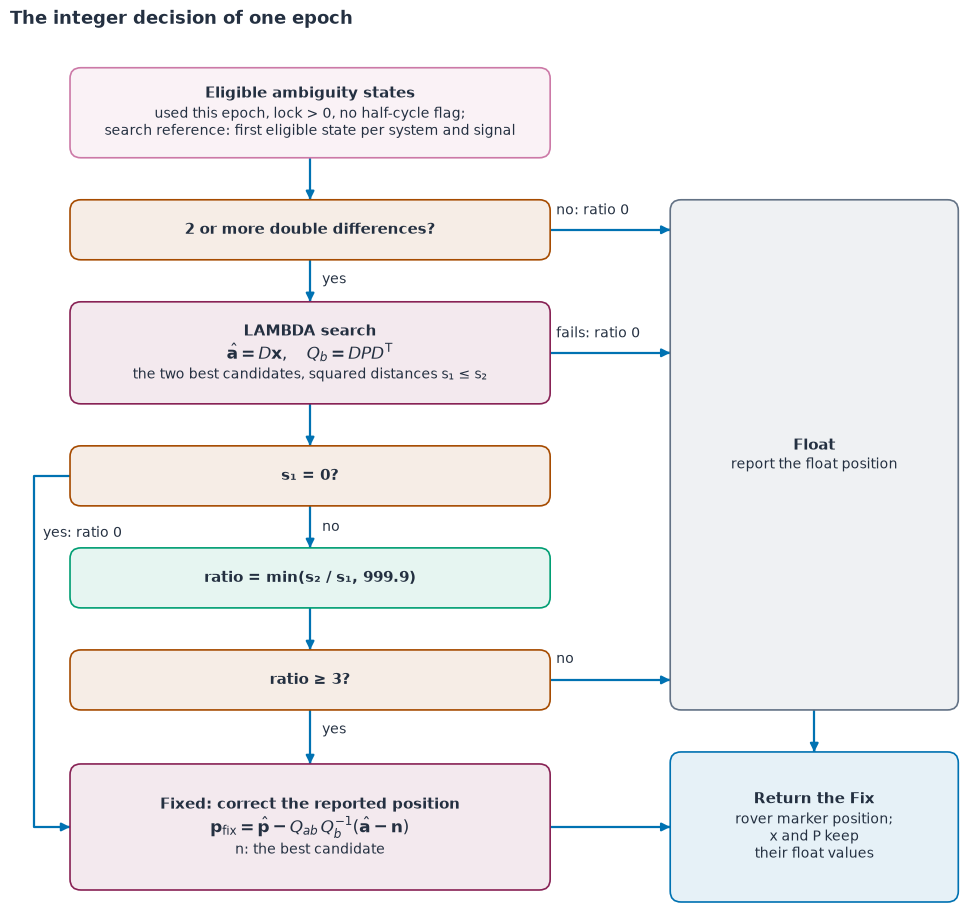

In [9]:
fig, ax = diagram_canvas(16, 14.6, "The integer decision of one epoch")
X0, W = 1.0, 8.0
elig = diagram_box(
    ax, X0, 12.6, W, 1.5, "Eligible ambiguity states",
    "used this epoch, lock > 0, no half-cycle flag;\nsearch reference: first eligible state "
    "per system and signal", role="control",
)  # fmt: skip
two = diagram_box(ax, X0, 10.9, W, 1.0, "2 or more double differences?", role="highlight")
search = diagram_box(
    ax, X0, 8.5, W, 1.7, "LAMBDA search", "the two best candidates, squared distances s₁ ≤ s₂",
    formula=r"$\hat{\mathbf{a}} = D\mathbf{x},\quad Q_b = D P D^\mathsf{T}$", role="position",
)  # fmt: skip
zero = diagram_box(ax, X0, 6.8, W, 1.0, "s₁ = 0?", role="highlight")
ratio = diagram_box(ax, X0, 5.1, W, 1.0, "ratio = min(s₂ / s₁, 999.9)", role="measure")
test = diagram_box(ax, X0, 3.4, W, 1.0, "ratio ≥ 3?", role="highlight")
fixed = diagram_box(
    ax, X0, 0.4, W, 2.1, "Fixed: correct the reported position", "n: the best candidate",
    formula=r"$\mathbf{p}_{\mathrm{fix}} = \hat{\mathbf{p}} - Q_{ab}\,Q_b^{-1}"
    r"(\hat{\mathbf{a}} - \mathbf{n})$", role="position",
)  # fmt: skip
flt = diagram_box(ax, 11.0, 3.4, 4.8, 8.5, "Float", "report the float position",
                  role="context")
ret = diagram_box(
    ax, 11.0, 0.2, 4.8, 2.5, "Return the Fix", "rover marker position;\nx and P keep\ntheir "
    "float values", role="flow",
)  # fmt: skip
for upper, lower in ((elig, two), (two, search), (search, zero), (zero, ratio), (ratio, test),
                     (test, fixed)):
    diagram_arrow(ax, [upper.bottom, lower.top])
for box, text in ((two, "yes"), (zero, "no"), (test, "yes")):
    diagram_label(ax, box.bottom[0] + 0.2, box.y - 0.35, text, ha="left")
for box, text in ((two, "no: ratio 0"), (search, "fails: ratio 0"), (test, "no")):
    diagram_arrow(ax, [box.right, (flt.x, box.right[1])], text,
                  (X0 + W + 0.1, box.right[1] + 0.35), ha="left")
diagram_arrow(ax, [zero.left, (0.4, zero.left[1]), (0.4, fixed.left[1]), fixed.left])
diagram_label(ax, 0.55, 6.35, "yes: ratio 0", ha="left")
diagram_arrow(ax, [fixed.right, (ret.x, fixed.right[1])])
diagram_arrow(ax, [flt.bottom, ret.top])
plt.show()

### Reading the resolution figure

The code below prints the fixed-epoch statistics and draws the ratio and the fixed error. On
the station path every one of the 121 solved epochs is fixed, the first already at a ratio of
about 19. GPS L1 and L2 give two simultaneous phase measurements per satellite on a very
short baseline, where the shared broadcast-orbit and atmospheric errors cancel almost
completely, so the very first epoch separates its candidates clearly. This is a favourable
example. At minute 22, when G21's states restart after its loss of lock, the ratio drops to
about 9, the lowest of the hour, and still passes; the other satellites' ambiguities are
already well determined. On the synthetic path the ratio dips at minute 10, where G03's
states restart, and stays far above the threshold; its printed statistics come from its own
noise and planted slip.

The top panel has a logarithmic ratio axis with the acceptance threshold dashed; filled
circles are fixed epochs and open squares float ones, whose time spans are shaded. A
reported ratio of 0 would be drawn at 0.1 as an open triangle, since a log axis has no zero.
The bottom panel shows east, north and up error on the fixed epochs only.

fixed 121 of 121 epochs; fixed 3-D error mean 0.68 cm, 95th percentile 1.35 cm, max 1.99 cm
lowest ratio 8.9 at minute 22.0 (fix)


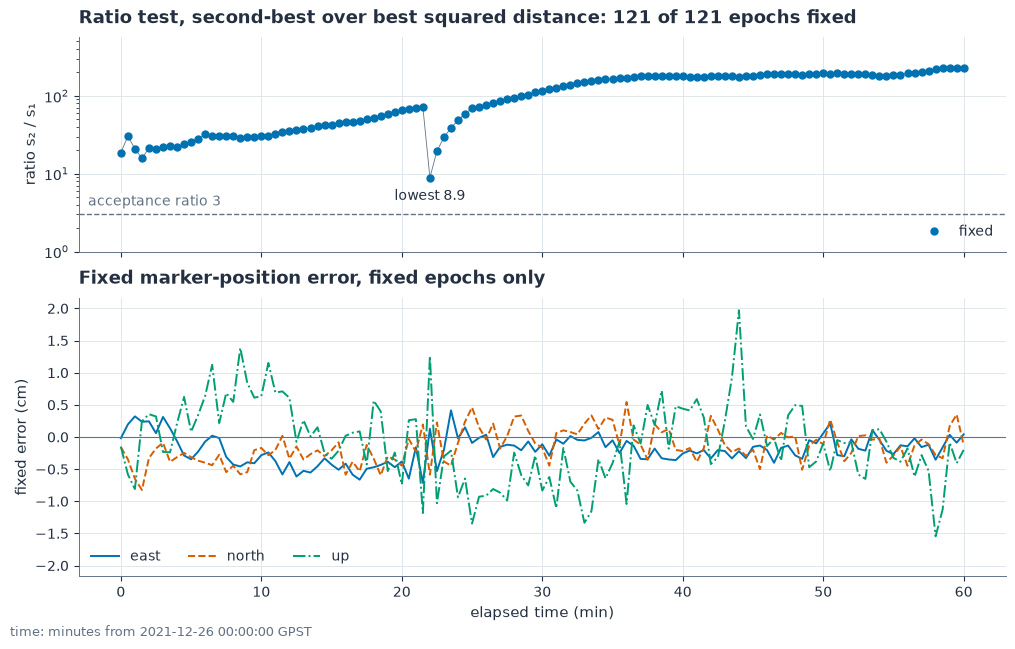

In [10]:
status = np.array([f.status == "fix" for f in fixes])
ratio = np.array([f.ratio for f in fixes])
fixed_err = enu(np.array([f.position for f in fixes]), truth)
# Euclidean marker-position distance, on the epochs the engine marked fixed.
d3 = np.linalg.norm(fixed_err[status], axis=1)
if status.any():
    print(f"fixed {status.sum()} of {len(fixes)} epochs; fixed 3-D error mean "
          f"{d3.mean() * 100:.2f} cm, 95th percentile {np.percentile(d3, 95) * 100:.2f} cm, "
          f"max {d3.max() * 100:.2f} cm")
else:
    print(f"no fixed epochs among {len(fixes)}")
low = int(np.argmin(np.where(ratio > 0, ratio, np.inf)))
print(f"lowest ratio {ratio[low]:.1f} at minute {tf[low]:.1f} ({fixes[low].status})")

fig, (ax_r, ax_e) = figure(2, 1, figsize=(10, 6.2), sharex=True,
                           gridspec_kw={"height_ratios": [1, 1.3]})
edges = np.concatenate([[tf[0]], (tf[1:] + tf[:-1]) / 2, [tf[-1]]])
for i in np.flatnonzero(~status):
    ax_r.axvspan(edges[i], edges[i + 1], color=LINES[1], alpha=0.12, linewidth=0)
# A log axis cannot draw zero: a reported 0 is drawn at 0.1 and never decides the status.
shown = np.where(ratio > 0, ratio, 0.1)
ax_r.plot(tf, shown, color=MUTED, linewidth=0.6)
for keep, marker, c, name in ((status & (ratio > 0), "o", LINES[0], "fixed"),
                              (~status & (ratio > 0), "s", LINES[1], "float"),
                              (ratio == 0, "v", HIGHLIGHT, "ratio 0, drawn at 0.1")):
    if keep.any():
        ax_r.plot(tf[keep], shown[keep], marker, color=c, markersize=5, linestyle="none",
                  markerfacecolor=c if name == "fixed" else "white", label=name)
ax_r.set_yscale("log")
bottom = 0.07 if (ratio == 0).any() else min(1.0, ratio[ratio > 0].min() / 2)
ax_r.set_ylim(bottom, max(30, ratio.max() * 2.5))
threshold_line(ax_r, opt.ratio_threshold, f"acceptance ratio {opt.ratio_threshold:g}")
ax_r.annotate(f"lowest {ratio[low]:.1f}", (tf[low], shown[low]), xytext=(0, -16),
              textcoords="offset points", ha="center", fontsize=10, color=INK)
ax_r.set_ylabel("ratio s₂ / s₁")
ax_r.set_title(f"Ratio test, second-best over best squared distance: "
               f"{status.sum()} of {len(fixes)} epochs fixed")
ax_r.legend(loc="lower right", ncol=3)
if status.any():
    err = np.where(status[:, None], fixed_err * 100, np.nan)
    lim = max(0.2, 1.1 * np.nanmax(np.abs(err)))
    for j, name in enumerate(("east", "north", "up")):
        ax_e.plot(tf, err[:, j], color=LINES[j], linestyle=("-", "--", "-.")[j], label=name)
    ax_e.set_ylim(-lim, lim)
    ax_e.legend(loc="lower left", ncol=3)
else:
    ax_e.text(0.5, 0.5, "no fixed epochs", transform=ax_e.transAxes, ha="center")
ax_e.axhline(0, color=MUTED, linewidth=0.8)
ax_e.set_ylabel("fixed error (cm)")
ax_e.set_xlabel("elapsed time (min)")
ax_e.set_title("Fixed marker-position error, fixed epochs only")
figure_note(fig, time_note(rover[0], synthetic))
plt.show()

### What the error statistics measure

The printed statistic is the distance from the reported rover marker position to the
reference marker, over the fixed epochs only: its mean, its 95th percentile and its maximum.
For the committed station run all 121 epochs are fixed, with a mean 3-D error of 0.68 cm, a
95th percentile of 1.35 cm and a maximum of 1.99 cm against the SINEX marker coordinates. On
the synthetic path the reference is the generating position, and the statistics describe
that simulation.

Differencing leaves receiver noise and multipath, the reflected signals that reach one
antenna differently from the other. The engine has no antenna phase-centre model. MATE and
MAT1 carry the same antenna type, so on an 11 m baseline their phase-centre patterns nearly
cancel in the double differences; noise and multipath, which differ between the two
antennas, remain. This notebook does not separate their shares of the remaining centimetre,
and neither a small formal covariance nor a large ratio measures them.

## 5. More signals

More satellites give the position more directions to be measured along. More signals from
the same satellite add observations at other wavelengths, each with its own ambiguity, and
the integer search must find a combination consistent with all of them. With $k$ eligible
satellites in one system and signal, the reference leaves $k-1$ double-differenced
ambiguities for that group. More observations help tell candidate vectors apart, though they
do not promise a better result at every epoch.

On the station path the next cell repeats the hour with GPS L5 (`G5Q`), Galileo E1 (`E1C`)
and Galileo E5a (`E5Q`) added to GPS L1/L2. GPS L5 and Galileo E5a share one carrier
frequency, with a wavelength of about 25.5 cm (printed below), and E1 shares L1's. The
engine uses every signal in one joint model; there is no separate wide-lane stage.
Double differences are formed within each system and each signal, against the highest
satellite that carries that signal, so L1 and L5 can use different reference satellites (not
every GPS satellite transmits L5). All the resulting ambiguities go into one integer search.

In the committed figure GPS L1/L2 uses six to seven satellites and the larger set eleven to
fourteen. These are `Fix.ns` counts, satellites used on each system's first signal, not a
count of signals. Both runs fix all 121 epochs, and the mean fixed 3-D error falls from
0.68 cm to 0.48 cm on this hour, and the 95th percentile from 1.35 cm to 0.91 cm. The right
panel shows the whole distribution of the fixed errors: the cumulative fraction of epochs at
or below each error. It moves towards smaller errors as a whole, which says nothing about
any single epoch.

Synthetic data: additional-signal run skipped (GPS L1/L2 only).

added carrier wavelengths: G5Q 25.5 cm, E1C 19.0 cm, E5Q 25.5 cm


121 epochs solved in 1 s
GPS L1/L2: fixed 121 of 121, mean error 0.68 cm; GPS + Galileo: fixed 121 of 121, mean error 0.48 cm


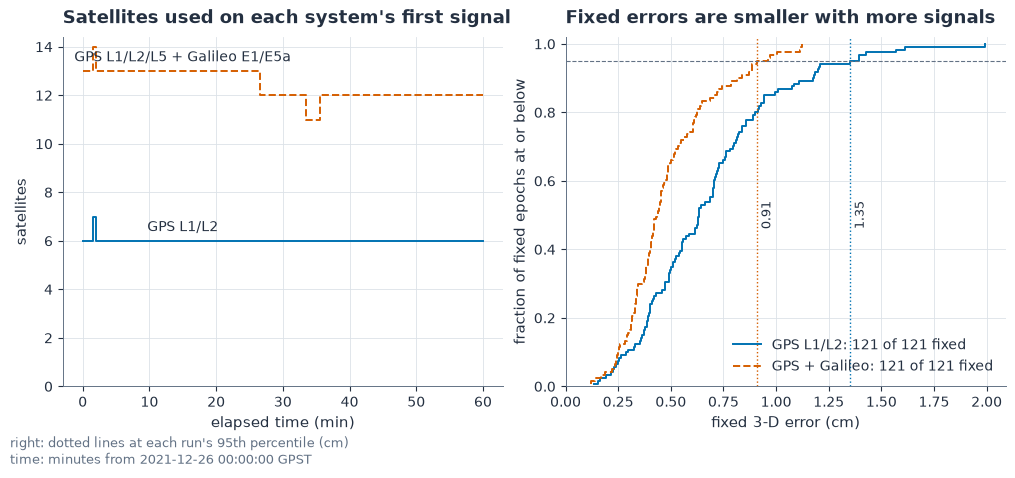

In [11]:
if synthetic:
    print("Synthetic data: additional-signal run skipped (GPS L1/L2 only).")
else:
    more = ("G1C", "G2W", "G5Q", "E1C", "E5Q")
    print("added carrier wavelengths: "
          + ", ".join(f"{g} {100 * wavelength(g):.1f} cm" for g in more[2:]))
    rover5 = read_rinex_observations(src.mat1_obs, more, RTK_WINDOW)
    base5 = read_rinex_observations(src.mate_obs, more, RTK_BASE_WINDOW)
    t0 = time.perf_counter()
    # A second run with more signals; the earlier figures keep the GPS L1/L2 results.
    fixes5 = solve_rtk(rover5, base5, ephs, station, rover_delta, opt)
    print(f"{len(fixes5)} epochs solved in {time.perf_counter() - t0:.0f} s")
    t5 = elapsed_minutes(fixes5, rover[0])
    status5 = np.array([f.status == "fix" for f in fixes5])
    err5 = np.linalg.norm(enu(np.array([f.position for f in fixes5]), truth), axis=1)
    print(f"GPS L1/L2: fixed {status.sum()} of {len(fixes)}, mean error {d3.mean() * 100:.2f} cm; "
          f"GPS + Galileo: fixed {status5.sum()} of {len(fixes5)}, "
          f"mean error {err5[status5].mean() * 100:.2f} cm")

    runs = (("GPS L1/L2", "GPS L1/L2", tf, fixes, d3, LINES[0], "-"),
            ("GPS L1/L2/L5 + Galileo E1/E5a", "GPS + Galileo", t5, fixes5, err5[status5],
             LINES[1], "--"))
    fig, (ax_n, ax_e) = figure(1, 2, figsize=(10, 4.3))
    for name, short, tt, ff, e, c, ls in runs:
        ns = [f.ns for f in ff]
        ax_n.step(tt, ns, where="post", color=c, linestyle=ls)
        mid = len(tt) // 4
        ax_n.annotate(name, (tt[mid], ns[mid]), xytext=(0, 7), textcoords="offset points",
                      ha="center", fontsize=10, color=INK)
        x = np.sort(e) * 100
        ax_e.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=c, linestyle=ls,
                  label=f"{short}: {len(x)} of {len(ff)} fixed")
        p95 = np.percentile(x, 95)
        ax_e.axvline(p95, color=c, linestyle=":", linewidth=1)
        ax_e.annotate(f"{p95:.2f}", (p95, 0.5), xytext=(3, 0), textcoords="offset points",
                      fontsize=9, color=INK, rotation=90, va="center")
    ax_n.set_ylim(0, None)
    ax_n.yaxis.get_major_locator().set_params(integer=True)
    ax_n.set(xlabel="elapsed time (min)", ylabel="satellites",
             title="Satellites used on each system's first signal")
    ax_e.axhline(0.95, color=MUTED, linestyle="--", linewidth=0.8)
    ax_e.set_xlim(0, 1.05 * max(d3.max(), err5[status5].max()) * 100)
    ax_e.set_ylim(0, 1.02)
    ax_e.set(xlabel="fixed 3-D error (cm)", ylabel="fraction of fixed epochs at or below",
             title="Fixed errors are smaller with more signals")
    ax_e.legend(loc="lower right")
    figure_note(fig, "right: dotted lines at each run's 95th percentile (cm)\n"
                + time_note(rover[0], synthetic))
    plt.show()

## 6. Comparison with RTKLIB

This comparison returns to the GPS L1/L2 run of sections 1 to 4. RTKLIB's `rnx2rtkp` reads the
same MAT1 rover, MATE base and broadcast navigation files over the same hour, set up as this
engine is: forward kinematic processing, GPS only, L1 plus L2, a 15° elevation mask,
continuous ambiguity resolution and a ratio threshold of 3, with the same base marker
coordinates and antenna height offsets. Its options for broadcast ionosphere and Saastamoinen
troposphere select RTKLIB's own single-baseline models; they do not mean either engine
corrects the ionosphere in its double differences.

The code counts each program's fixed epochs, then compares positions at the epochs where both
are fixed, matched by GPS week and time of week. The upper three panels show the signed
difference RTKLIB minus `pyrx` in each component, in millimetres; the bottom panel the 3-D
separation between the two fixed positions, a distance and so never negative.

In the committed hour both programs fix all 121 epochs, and their fixed positions differ by
0.08 mm on average and 0.14 mm at most. That agreement checks that the engine reproduces the
processing it follows, and is consistent with both choosing the same integers, although the
notebook does not compare RTKLIB's integer vectors directly. Accuracy is the separate
question answered in section 4, where the error against the station marker coordinates is at
the centimetre level; an error both programs share would not show here. Different signals,
base coordinates, antenna offsets, time windows, masks or ambiguity settings can make the
two disagree, so compare those first when reproducing the example elsewhere.

Synthetic data: comparison skipped (no external reference data). With station data the
comparison also needs `rnx2rtkp` on `PATH`.

RTKLIB fixed 121 of 121 epochs, pyrx 121 of 121; on the 121 epochs both fixed the positions differ by 0.08 mm mean, 0.14 mm max


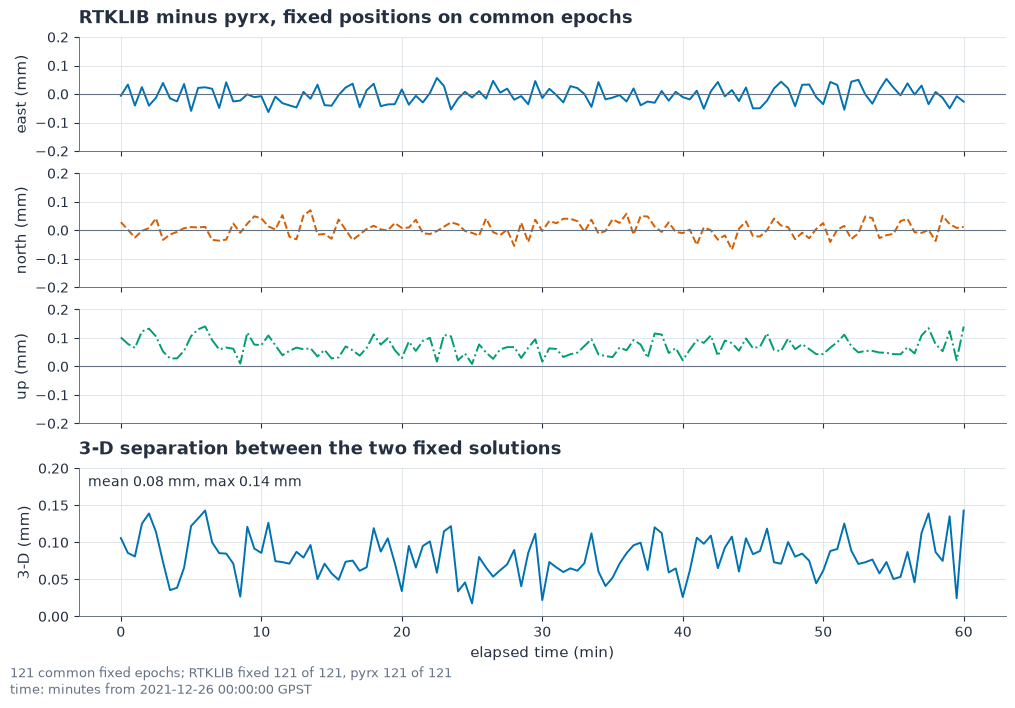

In [12]:
# The runner defaults to GPS-only L1/L2, matching `fixes`, not the larger signal set.
ref = None if synthetic else rnx2rtkp_rtk(
    src.mat1_obs, src.mate_obs, src.brdc_mixed, out, MATE_MARKER, hb.delta_enu[2],
    hr.delta_enu[2], RTK_SPAN,
)  # fmt: skip
if synthetic:
    print("Synthetic data: comparison skipped (no external reference data).")
elif ref is None:
    print("Comparison skipped: no RTKLIB solution.")
else:
    ref_fixed = {k: v for k, v in ref.items() if v["q"] == 1}
    keys = [(f.week, round(f.tow, 1)) for f in fixes]
    # Match epochs only where both engines report a fixed position.
    both = [(i, ref_fixed[k]["xyz"]) for i, k in enumerate(keys) if status[i] and k in ref_fixed]
    idx = np.array([i for i, _ in both])
    ref_err = enu(np.array([xyz for _, xyz in both]), truth)
    comp = (ref_err - fixed_err[idx]) * 1e3  # RTKLIB minus pyrx, mm
    # The distance between the two outputs; their marker errors are measured in section 4.
    diff = np.linalg.norm(comp, axis=1)
    print(f"RTKLIB fixed {len(ref_fixed)} of {len(ref)} epochs, pyrx {status.sum()} of "
          f"{len(fixes)}; on the {len(both)} epochs both fixed the positions differ by "
          f"{diff.mean():.2f} mm mean, {diff.max():.2f} mm max")

    tb = tf[idx]
    gaps = np.flatnonzero(np.diff(idx) > 1) + 1
    fig, axes = figure(4, 1, figsize=(10, 6.6), sharex=True,
                       gridspec_kw={"height_ratios": [1, 1, 1, 1.3]})
    lim = max(0.2, 1.1 * np.abs(comp).max())
    for j, name in enumerate(("east", "north", "up")):
        ax = axes[j]
        ax.plot(np.insert(tb, gaps, np.nan), np.insert(comp[:, j], gaps, np.nan),
                color=LINES[j], linestyle=("-", "--", "-.")[j])
        ax.axhline(0, color=MUTED, linewidth=0.8)
        ax.set_ylim(-lim, lim)
        ax.set_ylabel(f"{name} (mm)")
    axes[0].set_title("RTKLIB minus pyrx, fixed positions on common epochs")
    ax = axes[3]
    ax.plot(np.insert(tb, gaps, np.nan), np.insert(diff, gaps, np.nan), color=LINES[0])
    ax.set_ylim(0, max(0.2, 1.1 * diff.max()))
    ax.text(0.01, 0.95, f"mean {diff.mean():.2f} mm, max {diff.max():.2f} mm",
            transform=ax.transAxes, va="top", fontsize=10, color=INK)
    ax.set(ylabel="3-D (mm)", xlabel="elapsed time (min)",
           title="3-D separation between the two fixed solutions")
    figure_note(fig, f"{len(both)} common fixed epochs; RTKLIB fixed {len(ref_fixed)} of "
                f"{len(ref)}, pyrx {status.sum()} of {len(fixes)}\n"
                + time_note(rover[0], synthetic))
    plt.show()

## From samples to a fixed position

The three notebooks have now followed the whole computation: samples become tracked signals
and observables, observables and the broadcast orbits give a standalone fix, and a nearby
base turns carrier phase into a centimetre-level fix. The RTK hour here uses two IGS
stations' observation files, because the project's own L1 recording has no base receiver
beside it; the engine reads any RINEX pair the same way.

In the committed hour the GPS L1/L2 run fixes all 121 solved epochs, with a mean fixed 3-D
error against the rover marker of 0.68 cm and a 95th percentile of 1.35 cm; adding GPS L5
and Galileo E1/E5a brings the mean to 0.48 cm on this example. Synthetic data: the generated
pair and its planted slip exercise the same estimation steps without measuring real-world
accuracy.

The `pyrx-rtk` command runs the same engine on your own rover and base RINEX files; the
[package README](../README.md#rtk) describes its inputs, models and limits. For the geometry
and practical limits of a base and rover solution, continue with the
[RTK fundamentals](../../docs/fundamentals/09-rtk.md) and the
[glossary and further reading](../../docs/fundamentals/glossary.md#further-reading).